# NFL play prediction: project walkthrough

**Question:** How well does zero-shot JEV predict recorded dropbacks versus non-dropback runs compared with models trained on historical plays?

This notebook is the shared explanation and results viewer. Implementations live in `src/`.
**Run All is read-only:** no API calls, key access, downloads, model training, or 2025 evaluation.
The tables below distinguish saved development results from experiments still pending.


In [1]:
from pathlib import Path
import sys, json, csv, html
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "src/config.py").exists():
    raise RuntimeError("Open this notebook with NFLPredictor as the working directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import config
from src.jev import client, template

def read_json(relative):
    path = ROOT / relative
    return json.loads(path.read_text()) if path.exists() else None

def show_table(rows):
    if not rows:
        display(Markdown("No saved rows available."))
        return
    keys = list(rows[0])
    text = "| " + " | ".join(keys) + " |\n| " + " | ".join("---" for _ in keys) + " |\n"
    text += "\n".join("| " + " | ".join(str(row.get(k, "—")).replace("|", "/") for k in keys) + " |" for row in rows)
    display(Markdown(text))

print("Read-only walkthrough. Live inference is only available through explicit terminal commands.")


Read-only walkthrough. Live inference is only available through explicit terminal commands.


## 1. Experimental design

| Role | Seasons | Allowed use |
|---|---|---|
| Training | 2021–2023 | Fit preprocessing and specialists |
| Development | 2024 | Select hyperparameters and check JEV wording |
| Historical final test | 2025 | Evaluate once choices are frozen |
| Prospective secondary test | Future 2026 games | Still needs a freeze date and prespecified games |

All models see the same eight pre-snap facts. IDs are used to join predictions, never as inputs.
Descriptions, teams, labels and post-play statistics are excluded from the feature matrix and JEV request.


In [2]:
show_table([{"Input field": field, "Treatment": "categorical" if field in config.CATEGORICAL else "numeric"}
            for field in config.FEATURES])
assert len(config.FEATURES) == 8
assert not set(config.FEATURES) & {"qb_dropback", "desc", "game_id", "play_id", "pass_oe"}


| Input field | Treatment |
| --- | --- |
| down | categorical |
| ydstogo | numeric |
| yardline_100 | numeric |
| qtr | categorical |
| half_seconds_remaining | numeric |
| score_differential | numeric |
| posteam_timeouts_remaining | numeric |
| defteam_timeouts_remaining | numeric |

## 2. Data and labels

Each sample is one eligible regular-season run/pass snap. Exclude kneels, spikes,
two-point attempts, aborted/deleted plays, and missing required inputs or labels.
`qb_dropback = 1` includes pass attempts, sacks and scrambles; `0` is the non-dropback-run proxy.
This predicts the recorded category, not the coach's original intent or the optimal play.
RPOs and other ambiguous calls follow their recorded label; the data do not establish every original call.

The committed filter report demonstrates earlier processing of 2021–2024. It does not
by itself verify another season or a fresh rerun. Per-season class balances and feature
distributions remain a TA-requested deliverable. 2025 loading still needs a separate audit.


In [3]:
counts = read_json("results/filter_counts.json") or {}
show_table([{"Season": season, "Raw rows": row["raw_rows"], "Eligible plays": row["eligible"],
             "Missing features excluded": row["dropped_missing_feature"]}
            for season, row in counts.items()])
metrics = read_json("results/eval_dev/metrics.json")
if metrics:
    baseline = metrics["on_common_set"]["baseline"]
    c = baseline["confusion"]
    n_run, n_drop = c["tn"] + c["fp"], c["tp"] + c["fn"]
    show_table([{"2024 label": "Dropback", "Count": n_drop, "Share": f"{n_drop / baseline['n']:.2%}"},
                {"2024 label": "Non-dropback run", "Count": n_run, "Share": f"{n_run / baseline['n']:.2%}"}])
print("No raw data downloaded or held-out data loaded.")


| Season | Raw rows | Eligible plays | Missing features excluded |
| --- | --- | --- | --- |
| 2021 | 49922 | 33881 | 0 |
| 2022 | 49434 | 33544 | 0 |
| 2023 | 49665 | 33742 | 0 |
| 2024 | 49492 | 33224 | 0 |

| 2024 label | Count | Share |
| --- | --- | --- |
| Dropback | 20114 | 60.54% |
| Non-dropback run | 13110 | 39.46% |

No raw data downloaded or held-out data loaded.


## 3. Specialists and metrics

- **Constant baseline:** training-set dropback frequency for every play.
- **Logistic regression:** one-hot down/quarter; scale numeric inputs. Preprocessing is fitted on training only.
- **Gradient boosting:** nonlinear relationships, with down/quarter categorical.

Hyperparameters are selected by 2024 log loss. Accuracy and balanced accuracy describe
classification at probability 0.5. Brier score and log loss evaluate probabilities (lower
is better). Precision/recall and confusion matrices expose errors for each class.

The following are **saved development results**, not new fits or final test findings.


In [4]:
if metrics:
    display(Markdown(f"Saved comparison: **{metrics['common_set']['n_plays']:,} plays / {metrics['common_set']['n_games']} games**."))
    show_table([{"Model": name, "Accuracy": f"{m['accuracy']:.2%}",
                 "Balanced accuracy": f"{m['balanced_accuracy']:.2%}",
                 "Brier ↓": f"{m['brier']:.4f}", "Log loss ↓": f"{m['log_loss']:.4f}"}
                for name, m in metrics["on_common_set"].items()])
else:
    display(Markdown("No saved development metrics yet. Run the offline pipeline separately."))
selected = read_json("results/model_selection/selected.json")
if selected:
    show_table([{"Model": name, "Selected parameters": json.dumps(item["params"])}
                for name, item in selected.items()])


Saved comparison: **33,224 plays / 272 games**.

| Model | Accuracy | Balanced accuracy | Brier ↓ | Log loss ↓ |
| --- | --- | --- | --- | --- |
| baseline | 60.54% | 50.00% | 0.2389 | 0.6708 |
| gbt | 71.30% | 70.33% | 0.1787 | 0.5257 |
| logreg | 67.49% | 64.30% | 0.2020 | 0.5912 |

| Model | Selected parameters |
| --- | --- |
| baseline | {"train_rate": 0.609853015311317} |
| logreg | {"C": 10.0} |
| gbt | {"learning_rate": 0.03, "max_leaf_nodes": 31, "min_samples_leaf": 100} |

## 4. Calibration and learning curves

A calibrated model's predicted dropback probabilities match observed frequencies.
Points near the diagonal indicate agreement; sparse bins can be noisy.

Learning curves use nested subsets of training **games**, three subset seeds and fixed
selected hyperparameters. Error bars show variation across subset seeds, not confidence
intervals for final performance. The JEV reference will be added once available.


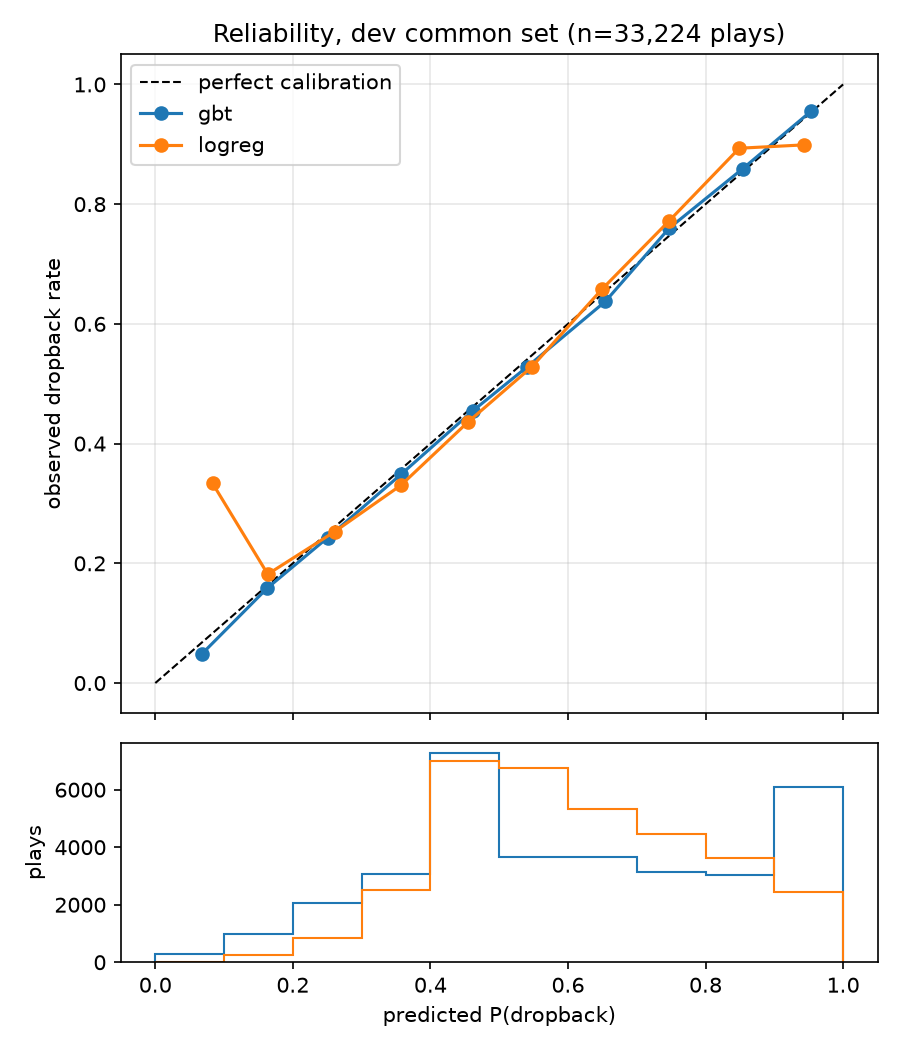

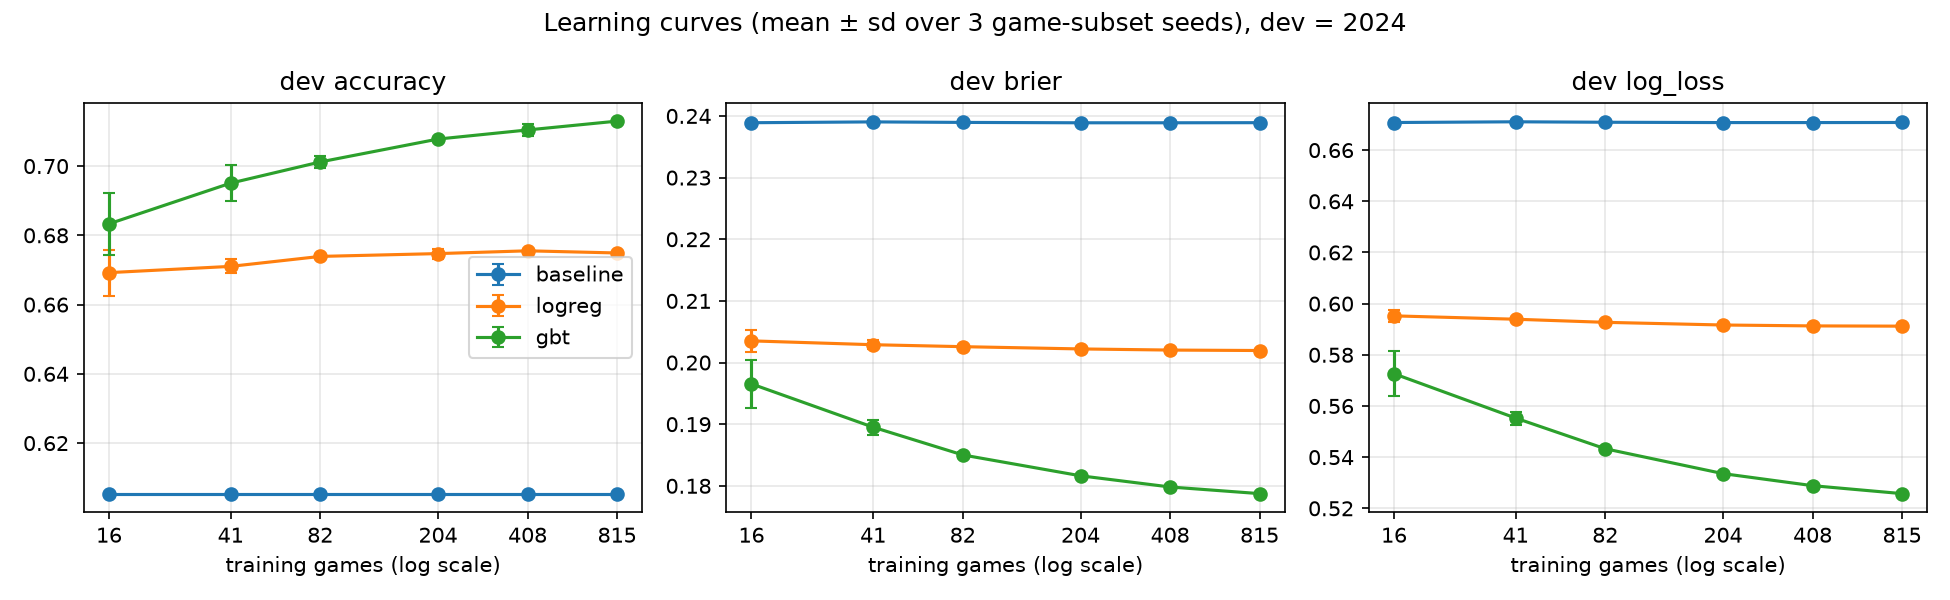

In [5]:
for filename in ["reliability_dev.png", "learning_curve_dev.png"]:
    path = ROOT / "results/figures" / filename
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"Not yet available: {filename}")


## 5. JEV request: build locally, never send

The direct HTTP client follows the original demo: a fixed state plus a Choice question
with two explicitly defined criteria. The pinned candidate model is `jev-1.13.0`.
Only the eight allowlisted fields enter the prompt. The following is a hypothetical
situation; it has no observed outcome or identifying information.

The key is not read by this notebook. Numeric/verbal and option-order sensitivity checks
are separate development experiments. The candidate is not frozen until live checks are reviewed.


In [6]:
example = dict(down=3, ydstogo=7, yardline_100=35, qtr=4,
               half_seconds_remaining=120, score_differential=-3,
               posteam_timeouts_remaining=2, defteam_timeouts_remaining=3)
# Fixed illustrative version, so an environment override cannot change this example.
example_model = "jev-1.13.0"
example_prompt = template.render(example)
example_payload = client.make_payload(example_model, example_prompt, template.labels())
print(json.dumps(example_payload, indent=2))
print("\nVerbal sensitivity variant:\n" + template.render(example, "verbal"))
print("\nReversed criteria keys:", template.labels(reverse=True))


{
  "model": "jev-1.13.0",
  "state": "NFL regular-season play, pre-snap situation (offense's perspective):\n- Down: 3\n- Yards to go for a first down: 7\n- Yards from the opponent's goal line: 35\n- Quarter: 4\n- Seconds remaining in the half: 120\n- Score differential (offense minus defense): -3\n- Offense timeouts remaining: 2\n- Defense timeouts remaining: 3\n\nBased only on the game situation before the snap, which kind of play did the offense run?",
  "questions": {
    "next_play": {
      "type": "choice",
      "instructions": "Predict the observed category of the next NFL offensive snap from the supplied pre-snap situation. The snap is known to be an eligible run or pass, excluding kneels, spikes, two-point attempts, aborted and deleted plays. Predict what the offense will do, rather than which play would be optimal. Only the provided situation is available; no team tendencies or play outcomes are given.",
      "criteria": {
        "dropback": "A quarterback dropback, inclu

## 6. JEV progress and controls

The implementation is ready for a bounded live pilot, which Charlie deferred.
**An offline test or preview is not a successful live pilot.** Existing responses from
the old demo are not reused for changed requests.

| Output | Location |
|---|---|
| Pilot reports | `results/jev/pilots/` |
| Secondary prompt variants | `results/jev/variants/` |
| Main predictions | `results/predictions/jev_dev.parquet` |
| Exact raw responses | Ignored `cache/jev-http-v2/` |

Every live command requires `--live --max-requests N`; otherwise it only previews or
explicitly replays cache. Cache misses cannot silently invoke inference. Attempts are
capped, requests have timeouts, no automatic retries occur, and completed responses are
validated and saved immediately. The cap applies per invocation, not to an account-wide budget.


In [7]:
pilot_dir = ROOT / "results/jev/pilots"
pilots = []
for path in sorted(pilot_dir.glob("*.json")) if pilot_dir.exists() else []:
    report = json.loads(path.read_text())
    pilots.append({"Report": path.name, "Status": report.get("status"),
                   "Plays": report.get("n_distinct_plays"),
                   "Requests sent in run": report.get("summary", {}).get("requests_sent"),
                   "Includes sensitivity checks": report.get("checks_included")})
show_table(pilots)
freeze = read_json("results/jev/prompt_freeze.json")
print("Prompt freeze:", "recorded (verify fingerprint before final use)" if freeze else "PENDING live checks and review")
print("Main JEV predictions present:", (ROOT / "results/predictions/jev_dev.parquet").exists())


No saved rows available.

Prompt freeze: PENDING live checks and review
Main JEV predictions present: False


### Deliberate terminal commands (documentation only)

These are Markdown, not executable notebook cells. Use the repo's virtual environment.
For another checkout, pass the saved 2024 CSV path with `--source`.

```sh
# Preview: always free, no key needed
.venv/bin/python -m src.jev.pilot --plays 20

# Paid opt-in, run only when ready; at most 20 new requests
.venv/bin/python -m src.jev.pilot --plays 20 --live --max-requests 20

# Exact replay, no network
.venv/bin/python -m src.jev.pilot --plays 20 --cache-only

# Preview sensitivity checks first (5 plays x 3 variants)
.venv/bin/python -m src.jev.pilot --plays 5 --checks
```

See README for live sensitivity checks, prompt freeze, and benchmark commands. A full
run is a separate decision after observing pilot usage and latency. Don't enable final
evaluation or select future games from their results.


## 7. Paired comparisons and situational errors

Comparisons resample whole games because plays within a game are correlated. Main
models use identical common plays; experimental variants cannot enter automatically.
Intervals below are saved, exploratory development comparisons after model selection.
The bootstrap tail fraction is not a calibrated hypothesis-test p-value.


In [8]:
paired = read_json("results/eval_dev/paired_bootstrap.json") or {}
show_table([{"Comparison (first − second)": name,
             "Accuracy difference": f"{r['accuracy']['diff'] * 100:+.2f} percentage points",
             "95% game-bootstrap interval": "[{:+.2f}, {:+.2f}] points".format(*[x * 100 for x in r['accuracy']['ci95']]),
             "Games": r["n_games"]} for name, r in paired.items()])
situation_path = ROOT / "results/eval_dev/situational.csv"
if situation_path.exists():
    with situation_path.open() as stream:
        situation_rows = list(csv.DictReader(stream))
    show_table([row for row in situation_rows if row["grouping"] == "by_down"])
    print("Other saved buckets: distance and late-game score. Bucket-specific confidence intervals remain to be added.")


| Comparison (first − second) | Accuracy difference | 95% game-bootstrap interval | Games |
| --- | --- | --- | --- |
| baseline - gbt | -10.76 percentage points | [-11.62, -9.94] points | 272 |
| baseline - logreg | -6.95 percentage points | [-7.75, -6.19] points | 272 |
| gbt - logreg | +3.81 percentage points | [+3.37, +4.24] points | 272 |

| grouping | bucket | model | n | dropback_rate | accuracy | balanced_accuracy | brier |
| --- | --- | --- | --- | --- | --- | --- | --- |
| by_down | 1 | baseline | 14582 | 0.49657111507337814 | 0.49657111507337814 | 0.5 | 0.2628210316696783 |
| by_down | 1 | gbt | 14582 | 0.49657111507337814 | 0.6305033603072281 | 0.6294748112171564 | 0.21380552296631855 |
| by_down | 1 | logreg | 14582 | 0.49657111507337814 | 0.5996433959676313 | 0.599592585479382 | 0.23291512498384637 |
| by_down | 2 | baseline | 11071 | 0.6250564537982115 | 0.6250564537982115 | 0.5 | 0.23459202790524053 |
| by_down | 2 | gbt | 11071 | 0.6250564537982115 | 0.7139373137024659 | 0.664073302902149 | 0.18854067609960165 |
| by_down | 2 | logreg | 11071 | 0.6250564537982115 | 0.6883750338722789 | 0.6390464620963261 | 0.2037046967870815 |
| by_down | 3 | baseline | 6811 | 0.8016443987667009 | 0.8016443987667009 | 0.5 | 0.19579459146040562 |
| by_down | 3 | gbt | 6811 | 0.8016443987667009 | 0.8703567758038467 | 0.7486842604718252 | 0.09622763825846219 |
| by_down | 3 | logreg | 6811 | 0.8016443987667009 | 0.8081045367787403 | 0.521576135436239 | 0.1362113443545607 |
| by_down | 4 | baseline | 760 | 0.6486842105263158 | 0.6486842105263158 | 0.5 | 0.22940086726199155 |
| by_down | 4 | gbt | 760 | 0.6486842105263158 | 0.8710526315789474 | 0.8662701035470368 | 0.10247779872682333 |
| by_down | 4 | logreg | 760 | 0.6486842105263158 | 0.7289473684210527 | 0.6442783234952253 | 0.1714083065773214 |

Other saved buckets: distance and late-game score. Bucket-specific confidence intervals remain to be added.


## 8. What remains and how to collaborate

1. Charlie: run/review bounded JEV pilot, sensitivity checks, freeze and benchmark.
2. Data owner: per-season class balances, feature distributions, label audit and 2025 loading confirmation.
3. Evaluation owner: situational uncertainty, shared JEV comparison and learning-curve reference.
4. Team: dated milestones, prospective 2026 freeze/game protocol, cached demo and report.

Keep reusable code in `src/`, small verified changes in pull requests, decisions in
`docs/decisions.md`, and AI assistance in `docs/ai_use_log.md`. Never commit keys.
A future-game test strengthens the contamination check; unknown historical pretraining
contents prevent attributing a result specifically to memorization or football knowledge.

### Sources

- [nflverse data](https://github.com/nflverse/nflverse-data/releases/tag/pbp), CC BY 4.0
- [nflverse field dictionary](https://raw.githubusercontent.com/nflverse/nflreadr/main/data-raw/dictionary_pbp.csv)
- [TypeSafe HTTP API](https://docs.typesafe.ai/api/system-one)
- [Choice](https://docs.typesafe.ai/primitives/choice)
- [Versioned models](https://docs.typesafe.ai/models)
